# 02 - Unicode attack generation

This notebook produces one shared attacked-test corpus so every classifier sees identical perturbations. It also measures where each attack is applicable, a necessary distinction because some Unicode transformations cannot change ordinary ASCII-heavy text.

**Inputs:** The processed test rows from notebook 01 and attack settings from `config/experiment.yaml`.  
**Outputs:** `attacks.parquet`, attack coverage and example tables, and the coverage figure.

## Setup and attack definitions

The local helpers define eligible replacements, deterministic per-example random seeds, and an auditable modification log. A seed is derived from the global attack seed, example ID, family, and strength, so generation is reproducible without depending on row order.

In [1]:
import hashlib
import json
import random
import unicodedata
from pathlib import Path
import pandas as pd
import yaml

# Same path setup as notebook 00; repeated for independent execution.
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
CONFIG = yaml.safe_load((ROOT / 'config/experiment.yaml').read_text(encoding='utf-8'))

PATHS = {key: ROOT / value for key, value in CONFIG['paths'].items()}
for directory in (PATHS['attacks'].parent, PATHS['tables'], PATHS['figures'],):
    directory.mkdir(parents=True, exist_ok=True)

def stable_int(*parts, modulo=2**32 - 1):
    digest = hashlib.sha256('||'.join(map(str, parts)).encode('utf-8')).hexdigest()
    return int(digest[:16], 16) % modulo

HOMOGLYPH_MAP = {
    'A': ('Α', 'А'), 'B': ('Β', 'В'), 'C': ('Ϲ', 'С'), 'E': ('Ε', 'Е'),
    'H': ('Η', 'Н'), 'I': ('Ι', 'І'), 'J': ('Ј',), 'K': ('Κ', 'К'),
    'M': ('Μ', 'М'), 'N': ('Ν',), 'O': ('Ο', 'О'), 'P': ('Ρ', 'Р'),
    'S': ('Ѕ',), 'T': ('Τ', 'Т'), 'X': ('Χ', 'Х'), 'Y': ('Υ', 'У'), 'Z': ('Ζ',),
    'a': ('а',), 'c': ('с',), 'e': ('е',), 'h': ('һ',), 'i': ('і',),
    'j': ('ј',), 'k': ('κ',), 'o': ('ο', 'о'), 'p': ('р',), 's': ('ѕ',),
    'x': ('х',), 'y': ('у',),
}

INVISIBLE_CHARS = tuple(chr(int(cp, 16)) for cp in CONFIG['attacks']['invisible_codepoints'])

def compatibility_candidate(ch):
    code = ord(ch)
    if 0x21 <= code <= 0x7E:
        candidate = chr(code + 0xFEE0)
        if unicodedata.normalize('NFKC', candidate) == ch:
            return candidate
    return None

def composition_candidate(ch):
    decomposed = unicodedata.normalize('NFD', ch)
    if decomposed != ch and unicodedata.normalize('NFC', decomposed) == unicodedata.normalize('NFC', ch):
        return decomposed
    return None

def codepoint_description(text):
    return [
        {'char': ch, 'codepoint': f'U+{ord(ch):04X}', 'name': unicodedata.name(ch, 'UNNAMED')}
        for ch in text
    ]

def options_for_position(ch, family):
    options = []
    if family in {'homoglyph', 'mixed'} and ch in HOMOGLYPH_MAP:
        options.extend(('homoglyph', candidate) for candidate in HOMOGLYPH_MAP[ch])
    if family in {'invisible', 'mixed'} and ch.isalnum():
        options.extend(('invisible', ch + candidate) for candidate in INVISIBLE_CHARS)
    if family in {'compatibility', 'mixed'}:
        candidate = compatibility_candidate(ch)
        if candidate is not None:
            options.append(('compatibility', candidate))
    if family in {'composition', 'mixed'}:
        candidate = composition_candidate(ch)
        if candidate is not None:
            options.append(('composition', candidate))
    return options

def attack_text(text, family, strength, seed, example_id):
    if family not in CONFIG['attacks']['families']:
        raise ValueError(f'Unknown attack family: {family}')
    options = {idx: options_for_position(ch, family) for idx, ch in enumerate(text)}
    options = {idx: values for idx, values in options.items() if values}
    eligible = sorted(options)
    if not eligible or strength <= 0:
        return {'attacked_text': text, 'eligible_count': len(eligible), 'changed_count': 0, 'effective_strength': 0.0, 'modification_log': '[]'}
    budget = min(len(eligible), max(1, int(round(strength * len(eligible)))))
    rng = random.Random(stable_int(seed, example_id, family, f'{strength:.4f}'))
    selected = sorted(rng.sample(eligible, budget))
    replacements = {}
    log = []
    for idx in selected:
        applied_family, replacement = rng.choice(options[idx])
        replacements[idx] = (applied_family, replacement)
        log.append({
            'index': idx, 'family': applied_family,
            'source': codepoint_description(text[idx]),
            'replacement': codepoint_description(replacement),
        })
    attacked = ''.join(replacements[idx][1] if idx in replacements else ch for idx, ch in enumerate(text))
    return {
        'attacked_text': attacked,
        'eligible_count': len(eligible),
        'changed_count': len(selected),
        'effective_strength': len(selected) / len(eligible),
        'modification_log': json.dumps(log, ensure_ascii=True, separators=(',', ':')),
    }

def visible_unicode(text):
    return ''.join(ch if ch.isprintable() and ch not in INVISIBLE_CHARS else f'\\u{ord(ch):04X}' for ch in text)


## Generate the condition matrix

For every official test example, the notebook applies five attack families at four strengths and three seeds. The nominal strength controls the fraction of eligible positions selected, with at least one change when eligibility is nonzero. Clean text, attacked text, labels, and modification metadata remain together for downstream alignment.

In [2]:
data = pd.read_parquet(PATHS['processed_data'])
test = data[data['split'] == 'test'].copy()
records = []
for row in test.itertuples(index=False):
    for family in CONFIG['attacks']['families']:
        for strength in CONFIG['attacks']['strengths']:
            for attack_seed in CONFIG['attacks']['seeds']:
                result = attack_text(row.text, family, float(strength), int(attack_seed), row.example_id)
                records.append({
                    'dataset': row.dataset, 'example_id': row.example_id, 'label': int(row.label),
                    'label_name': row.label_name, 'clean_text': row.text, 'attacked_text': result['attacked_text'],
                    'attack': family, 'strength': float(strength), 'attack_seed': int(attack_seed),
                    'eligible_count': result['eligible_count'], 'changed_count': result['changed_count'],
                    'effective_strength': result['effective_strength'], 'modification_log': result['modification_log'],
                })


## Attack coverage

Coverage is the fraction of generated rows whose text actually changed. `eligible_examples` counts examples with at least one alterable position, `mean_changes` records the average number of edited positions, and `mean_effective_strength` measures edits relative to eligible positions.

The full table is saved for analysis; the notebook displays only the configured primary strength to keep the output compact.

In [3]:
attacks = pd.DataFrame.from_records(records)
attacks.to_parquet(PATHS['attacks'], index=False)

coverage = attacks.groupby(['dataset', 'attack', 'strength']).agg(
    examples=('example_id', 'nunique'), eligible_examples=('eligible_count', lambda values: int((values > 0).sum() / len(CONFIG['attacks']['seeds']))),
    coverage=('changed_count', lambda values: float((values > 0).mean())), mean_changes=('changed_count', 'mean'),
    mean_effective_strength=('effective_strength', 'mean'),
).reset_index()
coverage.to_csv(PATHS['tables'] / 'attack_coverage.csv', index=False)
coverage[coverage['strength'] == CONFIG['analysis']['primary_strength']].reset_index(drop=True)


,dataset,attack,strength,examples,eligible_examples,coverage,mean_changes,mean_effective_strength
0,banking77,compatibility,0.2,3080,3080,1.0,8.850649,0.200154
1,banking77,composition,0.2,3080,0,0.0,0.000000,0.000000
2,banking77,homoglyph,0.2,3080,3080,1.0,4.859416,0.200293
3,banking77,invisible,0.2,3080,3080,1.0,8.541883,0.199700
4,banking77,mixed,0.2,3080,3080,1.0,8.850649,0.200154
5,trec,compatibility,0.2,500,500,1.0,5.882000,0.200056
6,trec,composition,0.2,500,0,0.0,0.000000,0.000000
7,trec,homoglyph,0.2,500,500,1.0,3.260000,0.200041
8,trec,invisible,0.2,500,500,1.0,5.642000,0.200455
9,trec,mixed,0.2,500,500,1.0,5.882000,0.200056


## Visual and auditable examples

The figure shows how effective coverage grows with nominal strength. One changed example per dataset and attack is exported with invisible characters escaped and a code-point-level modification log, making visually subtle attacks inspectable.

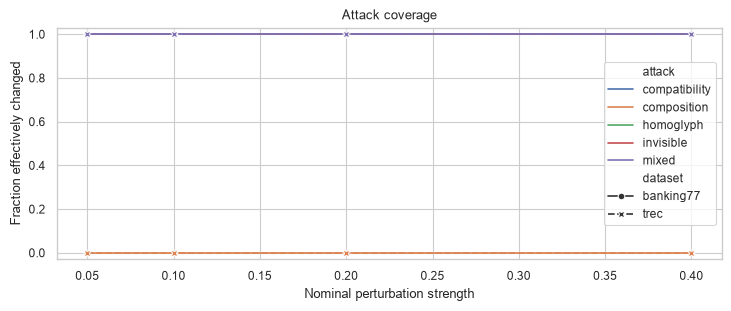

,dataset,attack,visible_clean,visible_attacked
6,banking77,homoglyph,How do I locate my card?,Hοw do I locate my сard?
18,banking77,invisible,How do I locate my card?,Ho\u200Dw do I\u200B l\uFEFFocate my card\u200B?
30,banking77,compatibility,How do I locate my card?,How dｏ I ｌocate ｍy carｄ?
54,banking77,mixed,How do I locate my card?,How ｄо Ｉ locate my\u200B card?
184806,trec,homoglyph,How far is it from Denver to Aspen ?,How far is it from Denvеr to Αѕpen ?
184818,trec,invisible,How far is it from Denver to Aspen ?,How far\u200C is it from\u200C Den\u2060v\u200...
184830,trec,compatibility,How far is it from Denver to Aspen ?,Hｏw far ｉｓ it from Ｄenver to Asｐeｎ ?
184854,trec,mixed,How far is it from Denver to Aspen ?,Ho\u2060w f\u2060aｒ i\uFEFFs it\u2060 from D\u...


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', context='paper')
fig, ax = plt.subplots(figsize=(7.2, 3.0), constrained_layout=True)
sns.lineplot(data=coverage, x='strength', y='coverage', hue='attack', style='dataset', markers=True, dashes=True, ax=ax)
ax.set(xlabel='Nominal perturbation strength', ylabel='Fraction effectively changed', ylim=(-0.03, 1.03), title='Attack coverage')
fig.savefig(PATHS['figures'] / 'attack_coverage.pdf', bbox_inches='tight')
plt.show()

examples = attacks[(attacks['strength'] == 0.20) & (attacks['attack_seed'] == 13) & (attacks['changed_count'] > 0)].groupby(['dataset', 'attack'], group_keys=False).head(1).copy()
examples['visible_clean'] = examples['clean_text'].map(visible_unicode)
examples['visible_attacked'] = examples['attacked_text'].map(visible_unicode)
examples[['dataset', 'attack', 'example_id', 'visible_clean', 'visible_attacked', 'modification_log']].to_csv(PATHS['tables'] / 'attack_examples.csv', index=False)
examples[['dataset', 'attack', 'visible_clean', 'visible_attacked']]


## Interpretation

Performance drops must be read together with coverage. Canonical-composition attacks may have zero eligible examples in these English datasets; in that case unchanged full-set performance is a property of applicability, not evidence that the model resisted an effective attack.